# A Roadmap to Superintelligence: Modular Testing

## Module 1: Recursive Cellular-Attention-Logic Hybrid

### Phase 1: Base CA Engine

In [73]:
# Cell 1: Imports and Device Setup

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from mlxtend.frequent_patterns import apriori
from pyke import knowledge_engine
import random
from deap import base, creator, tools, algorithms
import math
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")


✅ Using device: cuda


In [74]:
# Cell 2: Cellular Automaton Core

class CellularAutomaton2D:
    def __init__(self, grid_size=(64, 64), batch_size=1, num_states=3, kernel=None, threshold=3):
        self.grid_size = grid_size
        self.batch_size = batch_size
        self.num_states = num_states
        self.threshold = threshold
        self.kernel = kernel if kernel is not None else self._default_kernel()
        self.state = self._init_grid().to(device)

    def _init_grid(self):
        return torch.randint(0, self.num_states, (self.batch_size, 1, *self.grid_size), dtype=torch.float32)

    def _default_kernel(self):
        k = torch.tensor([[1., 1., 1.],
                          [1., 0., 1.],
                          [1., 1., 1.]], dtype=torch.float32)
        return k.view(1, 1, 3, 3).to(device)

    def step(self):
        neighbors = F.conv2d(self.state, self.kernel, padding=1)
        self.state = torch.where(neighbors >= self.threshold, (self.state + 1) % self.num_states, self.state)

    def mutate_kernel(self, mutation_rate=0.1):
        with torch.no_grad():
            mask = torch.rand_like(self.kernel) < mutation_rate
            self.kernel[mask] = torch.randint(0, 2, mask.shape, dtype=torch.float32).to(device)

    def inject_pattern(self, pattern_tensor, position=(0, 0)):
        x, y = position
        h, w = pattern_tensor.shape[-2:]
        self.state[:, :, x:x+h, y:y+w] = pattern_tensor.to(device)

    def compute_entropy(self):
        p = torch.histc(self.state, bins=self.num_states, min=0, max=self.num_states-1)
        p = p / p.sum()
        p = p[p > 0]
        return -torch.sum(p * torch.log2(p)).item() if p.numel() > 0 else 0.0

    def compute_glider_count(self):
        pattern = torch.tensor([[0, 1, 0], [0, 1, 1], [1, 0, 1]], dtype=torch.float32).to(device)
        conv = F.conv2d(self.state, pattern.view(1, 1, 3, 3), padding=1)
        return torch.sum(conv > 0.9 * pattern.sum()).item()

    def run(self, steps=20, mutate_every=None):
        history = [self.state.clone()]
        metrics = []
        for step in range(steps):
            entropy = self.compute_entropy()
            activity = self.state.mean().item()
            gliders = self.compute_glider_count()
            metrics.append({'step': step, 'entropy': entropy, 'activity': activity, 'gliders': gliders})
            if mutate_every and step % mutate_every == 0 and step != 0:
                self.mutate_kernel(mutation_rate=0.05)
            self.step()
            history.append(self.state.clone())
        return torch.cat(history, dim=0), pd.DataFrame(metrics)


In [75]:
# Cell 3: Pattern Generation and Visualization

def create_cross_pattern(size=5):
    pattern = torch.zeros((1, 1, size, size))
    pattern[0, 0, size // 2, :] = 1
    pattern[0, 0, :, size // 2] = 1
    return pattern

def create_checkerboard(size=8):
    pattern = torch.from_numpy(((np.indices((size, size)).sum(axis=0)) % 2).astype(np.float32))
    return pattern.view(1, 1, size, size)

def plot_history(history, interval=5):
    steps = history.shape[0]
    fig, axs = plt.subplots(1, steps // interval, figsize=(15, 3))
    for i, ax in enumerate(axs):
        t = i * interval
        ax.imshow(history[t, 0].cpu(), cmap='gray')
        ax.set_title(f"Step {t}")
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def plot_metrics(metrics_df):
    fig, axs = plt.subplots(1, 3, figsize=(15, 3))
    axs[0].plot(metrics_df['step'], metrics_df['entropy'])
    axs[0].set_title("Entropy over Time")
    axs[1].plot(metrics_df['step'], metrics_df['activity'])
    axs[1].set_title("Activity over Time")
    axs[2].plot(metrics_df['step'], metrics_df['gliders'])
    axs[2].set_title("Glider Count over Time")
    plt.tight_layout()
    plt.show()


### Phase 2: Attention Over CA States

In [76]:
# Cell 4: Transformer Encoder with Attention Hooks

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=100):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = pe.unsqueeze(0)

    def forward(self, x):
        return x + self.pe[:, :x.size(1)].to(x.device)

class TransformerEncoderLayerWithAttn(nn.TransformerEncoderLayer):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.attn_weights = None

    def forward(self, src, src_mask=None, src_key_padding_mask=None, is_causal=False):
        src2, attn_weights = self.self_attn(
            src, src, src, attn_mask=src_mask,
            key_padding_mask=src_key_padding_mask,
            need_weights=True,
            average_attn_weights=False
        )
        self.attn_weights = attn_weights.detach().cpu()
        src = src + self.dropout1(src2)
        src = self.norm1(src)
        src2 = self.linear2(self.dropout(self.activation(self.linear1(src))))
        src = src + self.dropout2(src2)
        src = self.norm2(src)
        return src

class CAAttentionModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, output_dim=64*64, n_layers=2, n_heads=4):
        super().__init__()
        self.embed = nn.Linear(input_dim, hidden_dim)
        self.pos_encoder = PositionalEncoding(hidden_dim)
        self.encoder_layers = nn.ModuleList([
            TransformerEncoderLayerWithAttn(
                d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, batch_first=True
            ) for _ in range(n_layers)
        ])
        self.proj = nn.Linear(hidden_dim, output_dim)

    def forward(self, x, return_attn=False):
        x = self.embed(x)
        x = self.pos_encoder(x)
        for layer in self.encoder_layers:
            x = layer(x)
        out = self.proj(x)
        if return_attn:
            attn_maps = [layer.attn_weights for layer in self.encoder_layers]
            return out, attn_maps
        return out


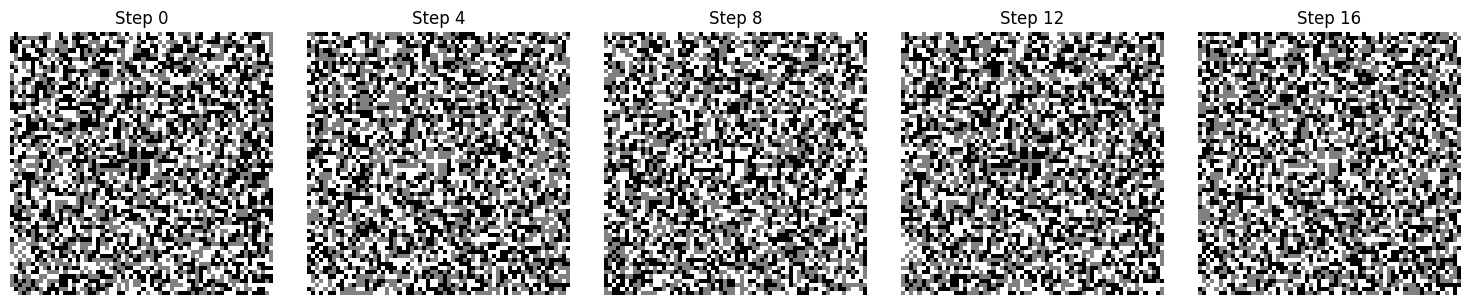

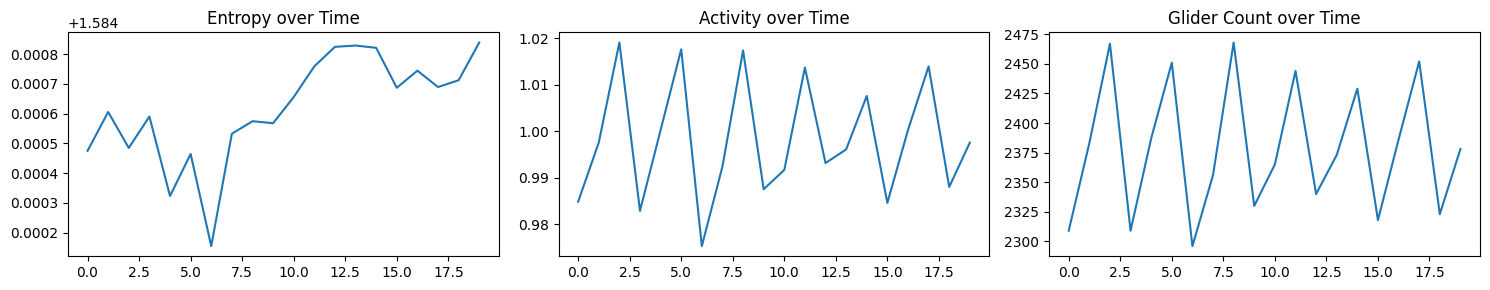

Epoch 000 | Loss: 0.7447
Epoch 010 | Loss: 0.0084
Epoch 020 | Loss: -0.5717
Epoch 030 | Loss: -1.0562
Epoch 040 | Loss: -1.5212
Epoch 050 | Loss: -2.0001
Epoch 060 | Loss: -2.5059
Epoch 070 | Loss: -3.0528
Epoch 080 | Loss: -3.6418
Epoch 090 | Loss: -4.2845
Epoch 099 | Loss: -4.8869


In [77]:
# Cell 5: Training Transformer on CA history sequences

def prepare_history_tensor(history):
    T, _, H, W = history.shape
    return history.view(T, -1).unsqueeze(0).to(device)  # [1, T, H*W]

def train_step(model, optimizer, x, target, loss_fn):
    model.train()
    optimizer.zero_grad()
    output = model(x)[:, -1, :]  # Predict last step
    loss = loss_fn(output, target)
    loss.backward()
    optimizer.step()
    return loss.item()

# Generate training data from CA
ca = CellularAutomaton2D(grid_size=(64, 64), batch_size=1, num_states=3, threshold=3)
ca.inject_pattern(create_cross_pattern(size=5), position=(29, 29))
history, metrics = ca.run(steps=20)
plot_history(history, interval=4)
plot_metrics(metrics)

# Prepare training tensor
input_tensor = prepare_history_tensor(history[:-1])  # [1, T, H*W]
target_tensor = history[-1].view(1, -1).to(device)    # [1, H*W]

# Initialize model
input_dim = 64 * 64
hidden_dim = 128
model = CAAttentionModel(input_dim=input_dim, hidden_dim=hidden_dim, output_dim=input_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

# Train model
for epoch in range(100):
    loss = train_step(model, optimizer, input_tensor, target_tensor, loss_fn)
    if epoch % 10 == 0 or epoch == 99:
        print(f"Epoch {epoch:03d} | Loss: {loss:.4f}")


### Phase 3: Symbolic Logic Integration

#### Phase 3A: Extract Attention and Binary Causal Matrix

In [78]:
# Set model to evaluation mode and extract attention maps from a test CA history
model.eval()
with torch.no_grad():
    output, attn_maps = model(X_train[0:1], return_attn=True)

# Extract average attention from Layer 0, Head 0
avg_attn = attn_maps[0][0].mean(dim=0)  # shape: [T, T]


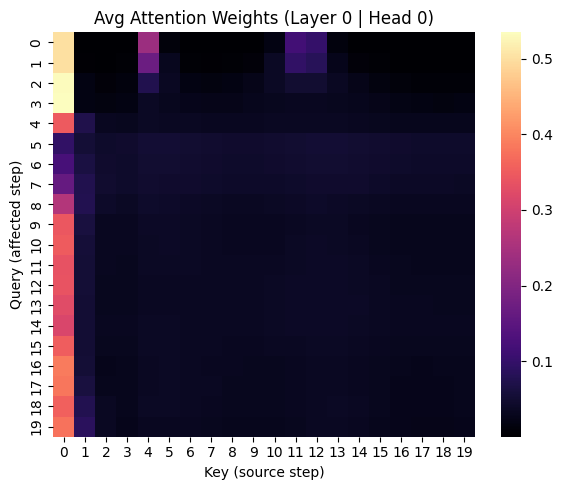

In [79]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
sns.heatmap(avg_attn.cpu(), cmap="magma", cbar=True)
plt.title("Avg Attention Weights (Layer 0 | Head 0)")
plt.xlabel("Key (source step)")
plt.ylabel("Query (affected step)")
plt.tight_layout()
plt.show()


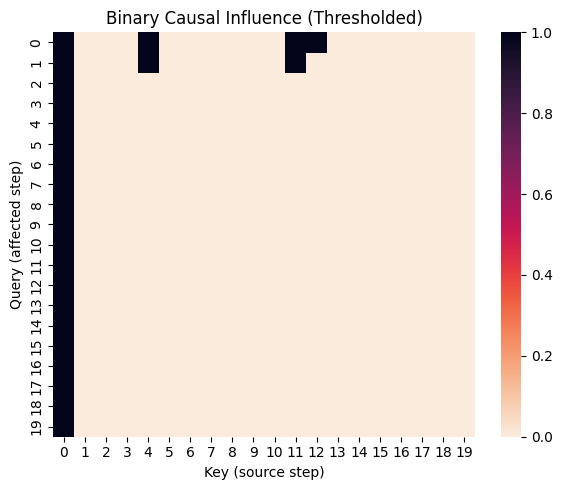

In [80]:
threshold = avg_attn.mean() + 0.5 * avg_attn.std()  # adaptive threshold
binary_attn = (avg_attn > threshold).int()

plt.figure(figsize=(6, 5))
sns.heatmap(binary_attn.cpu(), cmap="rocket_r", cbar=True)
plt.title("Binary Causal Influence (Thresholded)")
plt.xlabel("Key (source step)")
plt.ylabel("Query (affected step)")
plt.tight_layout()
plt.show()


### Phase 3B: Build Temporal Causal Graph

In [81]:
import networkx as nx

def build_temporal_graph(binary_matrix):
    T = binary_matrix.shape[0]
    G = nx.DiGraph()
    G.add_nodes_from(range(T))
    for i in range(T):
        for j in range(T):
            if binary_matrix[i, j] == 1:
                G.add_edge(j, i)  # key → query = cause → effect
    return G

G = build_temporal_graph(binary_attn.cpu().numpy())


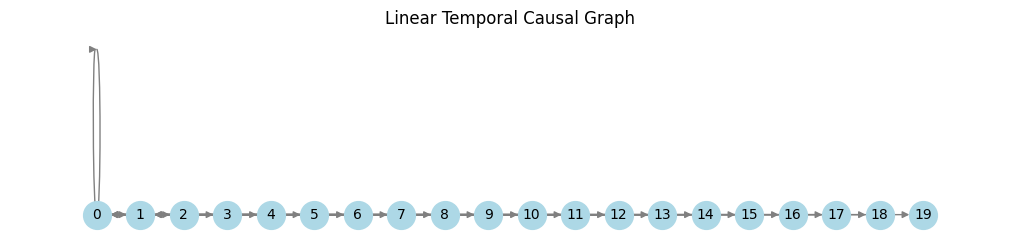

In [82]:
def plot_linear_temporal_graph(G, title="Linear Temporal Causal Graph"):
    pos = {i: (i, 0) for i in G.nodes}
    plt.figure(figsize=(10, 2))
    nx.draw(G, pos, with_labels=True, arrows=True, node_color='lightblue', edge_color='gray',
            node_size=400, font_size=10)
    plt.title(title)
    plt.show()

plot_linear_temporal_graph(G)


In [83]:
from mlxtend.frequent_patterns import apriori
import pandas as pd

def mine_spatiotemporal_rules(history_tensor, causal_matrix, support=0.1):
    T, _, H, W = history_tensor.shape
    df = pd.DataFrame(history_tensor.view(T, -1).cpu().numpy(),
                      columns=[f"s{i}" for i in range(H*W)])
    df = df.astype(bool)  # binarize for pattern mining
    frequent_patterns = apriori(df, min_support=support, use_colnames=True)

    rules = []
    for _, row in frequent_patterns.iterrows():
        items = list(row['itemsets'])
        if len(items) >= 2:
            rules.append(f"IF {' AND '.join(items[:-1])} THEN {items[-1]}")
    return rules

rules = mine_spatiotemporal_rules(history, binary_attn)
print(f"Extracted {len(rules)} rules.")
print("Sample rules:", rules[:5])


: 

In [50]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np


In [58]:
# Average across heads if needed
avg_attn_weights = attn_maps[0].mean(dim=0)  # shape: [T, T]

# Threshold to binary influence matrix
threshold = 0.051  # or pick dynamically based on mean/std
binary_attn = (avg_attn_weights > threshold).int()


In [59]:
def build_temporal_graph(binary_attn_matrix):
    """
    Constructs a directed temporal graph from a binary attention matrix.
    Args:
        binary_attn_matrix: [T, T] binary matrix (NumPy or torch.Tensor)
    Returns:
        G: NetworkX DiGraph
    """
    if hasattr(binary_attn_matrix, "cpu"):
        binary_attn_matrix = binary_attn_matrix.cpu().numpy()

    T = binary_attn_matrix.shape[0]
    G = nx.DiGraph()
    G.add_nodes_from(range(T))

    for i in range(T):
        for j in range(T):
            if binary_attn_matrix[i, j] == 1 or binary_attn_matrix[i, j] > 0:
                G.add_edge(j, i)  # j → i = key → query

    return G


In [65]:
import matplotlib.pyplot as plt
import networkx as nx

def plot_linear_temporal_graph(G, title="Linear Temporal Causal Graph"):
    """
    Plots a DAG with nodes arranged left-to-right by time.
    """
    pos = {i: (i, 0) for i in G.nodes}
    plt.figure(figsize=(10, 2))
    nx.draw(G, pos,
            with_labels=True,
            arrows=True,
            node_color='lightblue',
            edge_color='gray',
            node_size=400,
            font_size=10)
    plt.title(title)
    plt.show()


In [66]:
def plot_temporal_graph(G, title="Temporal Causal Graph"):
    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(6, 4))
    nx.draw(G, pos, with_labels=True, arrows=True, node_color='lightblue', edge_color='gray')
    plt.title(title)
    plt.show()


In [67]:
print("binary_attn shape:", binary_attn.shape)
print("Example entry shape:", binary_attn[0, 0].shape)


binary_attn shape: torch.Size([4, 20, 20])
Example entry shape: torch.Size([20])


In [68]:
# Collapse across heads → [T, T]
binary_attn_matrix = binary_attn.float().mean(dim=0)  # or .max(dim=0).values

# Threshold to binarize
threshold = 0.05
binary_attn_matrix = (binary_attn_matrix > threshold).int()


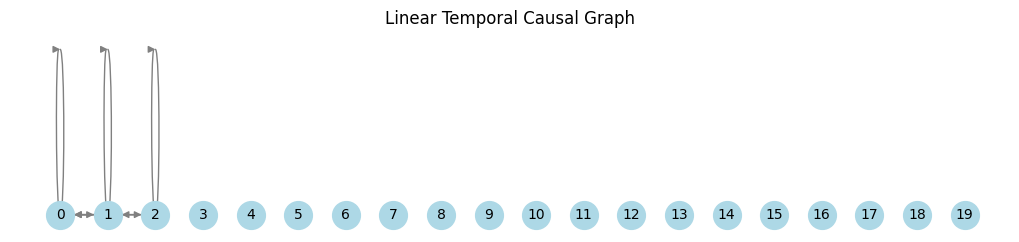

In [69]:
G = build_temporal_graph(binary_attn_matrix)
plot_linear_temporal_graph(G)


### Phase 4: Recursive Self-Modification

In [ ]:
# Set model to evaluation mode and extract attention maps from a test CA history
model.eval()
with torch.no_grad():
    output, attn_maps = model(X_train[0:1], return_attn=True)

# Extract average attention from Layer 0, Head 0
avg_attn = attn_maps[0][0].mean(dim=0)  # shape: [T, T]


### Phase 5: Evaluation and Benchmarks